#### Importing Libraries

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Model Explainability Libraries Imported Successfully")

Model Explainability Libraries Imported Successfully


#### Configuring Project Directories

In [2]:
project_dir = Path("..").resolve()

data_dir = project_dir / "data" / "processed"
models_dir = project_dir / "models"
artifacts_dir = project_dir / "artifacts"
reports_dir = project_dir / "reports"
figures_dir = reports_dir / "figures"

required_directories = {
    "Processed Data": data_dir,
    "Models": models_dir,
    "Artifacts": artifacts_dir,
    "Reports": reports_dir,
    "Figures": figures_dir
}

for name, directory in required_directories.items():
    assert directory.is_dir(), f"Directory not found: {directory}"
    print(f"{name}: {directory}")

print("\nProject Directories Configured Successfully")

Processed Data: D:\Projects\ML and Data Science\Retail Sales Dynamics\data\processed
Models: D:\Projects\ML and Data Science\Retail Sales Dynamics\models
Artifacts: D:\Projects\ML and Data Science\Retail Sales Dynamics\artifacts
Reports: D:\Projects\ML and Data Science\Retail Sales Dynamics\reports
Figures: D:\Projects\ML and Data Science\Retail Sales Dynamics\reports\figures

Project Directories Configured Successfully


#### Loading Trained Models and Configuration Artifacts

In [3]:
with open(
    artifacts_dir / "forecast_feature_config.json",
    "r",
    encoding="utf-8"
) as file:
    feature_config = json.load(file)

with open(
    artifacts_dir / "final_forecasting_configuration.json",
    "r",
    encoding="utf-8"
) as file:
    final_model_config = json.load(file)

with open(
    artifacts_dir / "model_evaluation_summary.json",
    "r",
    encoding="utf-8"
) as file:
    evaluation_summary = json.load(file)

extra_trees_models = joblib.load(
    models_dir / "final_extra_trees.joblib"
)

autoreg_model = joblib.load(
    models_dir / "final_autoreg.pkl"
)

sarima_model = joblib.load(
    models_dir / "final_sarima.pkl"
)

forecast_horizon = int(feature_config["forecast_horizon"])

assert forecast_horizon == 7
assert len(extra_trees_models) == forecast_horizon

print("Final Model:", final_model_config["model_name"])
print("Forecast Horizon:", forecast_horizon)
print("Extra Trees Models Loaded:", len(extra_trees_models))
print("AutoReg Model Loaded:", type(autoreg_model).__name__)
print("SARIMA Model Loaded:", type(sarima_model).__name__)
print("Evaluation Summary Loaded:", bool(evaluation_summary))

print("\nTrained Models and Configuration Artifacts Loaded Successfully")

Final Model: Voting_Hybrid
Forecast Horizon: 7
Extra Trees Models Loaded: 7
AutoReg Model Loaded: AutoRegResultsWrapper
SARIMA Model Loaded: SARIMAXResultsWrapper
Evaluation Summary Loaded: True

Trained Models and Configuration Artifacts Loaded Successfully


#### Loading Feature Datasets and Evaluation Results

In [4]:
train_df = pd.read_parquet(
    data_dir / "forecast_features_train.parquet"
)

test_df = pd.read_parquet(
    data_dir / "forecast_features_test.parquet"
)

daily_revenue_df = pd.read_parquet(
    data_dir / "daily_revenue.parquet"
)

rolling_predictions_df = pd.read_parquet(
    artifacts_dir / "rolling_test_predictions.parquet"
)

forecast_error_df = pd.read_parquet(
    artifacts_dir / "forecast_error_analysis.parquet"
)

horizon_performance_df = pd.read_csv(
    artifacts_dir / "horizon_wise_performance.csv"
)

test_performance_df = pd.read_csv(
    artifacts_dir / "test_model_performance.csv"
)

loaded_datasets = {
    "Training Features": train_df,
    "Test Features": test_df,
    "Daily Revenue": daily_revenue_df,
    "Rolling Predictions": rolling_predictions_df,
    "Forecast Errors": forecast_error_df,
    "Horizon Performance": horizon_performance_df,
    "Test Performance": test_performance_df
}

print("Loaded Dataset Dimensions:\n")

for name, dataframe in loaded_datasets.items():
    print(f"{name}: {dataframe.shape}")

assert len(train_df) == 207
assert len(test_df) == 55
assert len(daily_revenue_df) == 305
assert len(rolling_predictions_df) == 385

print("\nFeature Datasets and Evaluation Results Loaded Successfully")

Loaded Dataset Dimensions:

Training Features: (207, 87)
Test Features: (55, 87)
Daily Revenue: (305, 2)
Rolling Predictions: (385, 12)
Forecast Errors: (385, 16)
Horizon Performance: (42, 6)
Test Performance: (6, 7)

Feature Datasets and Evaluation Results Loaded Successfully


#### Verifying Horizon-Specific Feature Mappings

In [6]:
shared_features = feature_config["shared_features"]
horizon_features = feature_config["horizon_features"]
horizon_targets = feature_config["horizon_targets"]

print("Feature Configuration Structure:")
print("Shared Features Type:", type(shared_features).__name__)
print("Horizon Features Type:", type(horizon_features).__name__)
print("Horizon Feature Keys:", list(horizon_features.keys()))

print("\nHorizon-Specific Feature Diagnostics:\n")

diagnostic_records = []

for horizon in range(1, forecast_horizon + 1):
    model = extra_trees_models[horizon]
    horizon_key = str(horizon)

    configured_features = (
        shared_features + horizon_features[horizon_key]
    )

    model_features = list(
        getattr(model, "feature_names_in_", [])
    )

    diagnostic_records.append({
        "Horizon": horizon,
        "Shared_Features": len(shared_features),
        "Horizon_Features": len(horizon_features[horizon_key]),
        "Configured_Total": len(configured_features),
        "Model_Expected": model.n_features_in_,
        "Model_Feature_Names": len(model_features),
        "Count_Match": (
            len(configured_features) == model.n_features_in_
        )
    })

feature_diagnostic_df = pd.DataFrame(diagnostic_records)

display(feature_diagnostic_df)

print("\nHorizon 1 — Configured Feature Names:")
print(configured_features if forecast_horizon == 1 else (
    shared_features + horizon_features["1"]
))

print("\nHorizon 1 — Model Feature Names:")
print(
    list(
        getattr(
            extra_trees_models[1],
            "feature_names_in_",
            []
        )
    )
)

print("\nFeature Mapping Diagnostics Completed")

Feature Configuration Structure:
Shared Features Type: list
Horizon Features Type: dict
Horizon Feature Keys: ['1', '2', '3', '4', '5', '6', '7']

Horizon-Specific Feature Diagnostics:



,Horizon,Shared_Features,Horizon_Features,Configured_Total,Model_Expected,Model_Feature_Names,Count_Match
0,1,44,48,92,48,48,False
1,2,44,48,92,48,48,False
2,3,44,48,92,48,48,False
3,4,44,48,92,48,48,False
4,5,44,48,92,48,48,False
5,6,44,48,92,48,48,False
6,7,44,48,92,48,48,False



Horizon 1 — Configured Feature Names:
['Origin_Revenue', 'Revenue_Lag_1', 'Revenue_Lag_2', 'Revenue_Lag_3', 'Revenue_Lag_6', 'Revenue_Lag_7', 'Revenue_Lag_12', 'Revenue_Lag_14', 'Revenue_Lag_18', 'Revenue_Lag_24', 'Revenue_Lag_30', 'Revenue_Rolling_Mean_3', 'Revenue_Rolling_Std_3', 'Revenue_Rolling_Min_3', 'Revenue_Rolling_Max_3', 'Revenue_Rolling_Mean_6', 'Revenue_Rolling_Std_6', 'Revenue_Rolling_Min_6', 'Revenue_Rolling_Max_6', 'Revenue_Rolling_Mean_7', 'Revenue_Rolling_Std_7', 'Revenue_Rolling_Min_7', 'Revenue_Rolling_Max_7', 'Revenue_Rolling_Mean_14', 'Revenue_Rolling_Std_14', 'Revenue_Rolling_Min_14', 'Revenue_Rolling_Max_14', 'Revenue_Rolling_Mean_30', 'Revenue_Rolling_Std_30', 'Revenue_Rolling_Min_30', 'Revenue_Rolling_Max_30', 'Revenue_Change_1', 'Revenue_Change_6', 'Revenue_Change_12', 'Revenue_Momentum_3_7', 'Revenue_Momentum_7_30', 'Revenue_Ratio_3_7', 'Revenue_Ratio_7_30', 'Origin_Day_Of_Week', 'Origin_Day_Of_Month', 'Origin_Month', 'Origin_Quarter', 'Origin_Day_Of_Year', 

#### Verifying Horizon-Specific Feature Mappings

In [7]:
horizon_features = feature_config["horizon_features"]
horizon_targets = feature_config["horizon_targets"]

horizon_feature_columns = {}
horizon_target_columns = {}
feature_verification_records = []

for horizon in range(1, forecast_horizon + 1):
    horizon_key = str(horizon)

    feature_columns = horizon_features[horizon_key]
    target_column = horizon_targets[horizon_key]
    model = extra_trees_models[horizon]

    assert len(feature_columns) == len(set(feature_columns)), (
        f"Horizon {horizon}: Duplicate features detected"
    )

    assert all(
        column in train_df.columns and column in test_df.columns
        for column in feature_columns
    ), f"Horizon {horizon}: Missing feature columns"

    assert target_column in train_df.columns
    assert target_column in test_df.columns

    assert len(feature_columns) == model.n_features_in_, (
        f"Horizon {horizon}: Feature count mismatch"
    )

    assert list(model.feature_names_in_) == feature_columns, (
        f"Horizon {horizon}: Feature order mismatch"
    )

    horizon_feature_columns[horizon] = feature_columns
    horizon_target_columns[horizon] = target_column

    feature_verification_records.append({
        "Horizon": horizon,
        "Feature_Count": len(feature_columns),
        "Training_Origins": len(train_df),
        "Test_Origins": len(test_df),
        "Target": target_column,
        "Status": "Verified"
    })

feature_verification_df = pd.DataFrame(
    feature_verification_records
)

print("Horizon-Specific Feature Verification:\n")

display(feature_verification_df)

print("\nAll Horizon-Specific Feature Mappings Verified Successfully")

Horizon-Specific Feature Verification:



,Horizon,Feature_Count,Training_Origins,Test_Origins,Target,Status
0,1,48,207,55,Target_H1,Verified
1,2,48,207,55,Target_H2,Verified
2,3,48,207,55,Target_H3,Verified
3,4,48,207,55,Target_H4,Verified
4,5,48,207,55,Target_H5,Verified
5,6,48,207,55,Target_H6,Verified
6,7,48,207,55,Target_H7,Verified



All Horizon-Specific Feature Mappings Verified Successfully


**Key Observations**
- **Feature Consistency:** All seven Extra Trees models use 48 verified input features, with feature names and ordering matching their respective training configurations.
- **Horizon-Specific Modeling:** Each forecasting horizon has a dedicated model trained on 207 forecast origins, with 55 test origins available for evaluating feature contributions.

#### Calculating Extra Trees Feature Importance

In [8]:
feature_importance_records = []

for horizon in range(1, forecast_horizon + 1):
    model = extra_trees_models[horizon]
    feature_columns = horizon_feature_columns[horizon]

    importances = model.feature_importances_

    assert len(importances) == len(feature_columns)
    assert np.isclose(importances.sum(), 1.0)

    for feature, importance in zip(
        feature_columns,
        importances
    ):
        feature_importance_records.append({
            "Horizon": horizon,
            "Feature": feature,
            "Importance": float(importance)
        })

feature_importance_df = pd.DataFrame(
    feature_importance_records
)

average_feature_importance_df = (
    feature_importance_df
    .groupby("Feature", as_index=False)
    .agg(
        Mean_Importance=("Importance", "mean"),
        Horizons_Used=("Horizon", "nunique")
    )
    .sort_values(
        "Mean_Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Feature Importance Records:", len(feature_importance_df))
print("Unique Features:", feature_importance_df["Feature"].nunique())

print("\nTop 15 Features by Average Importance:\n")

display(
    average_feature_importance_df.head(15).style.format({
        "Mean_Importance": "{:.4f}"
    })
)

print("\nExtra Trees Feature Importance Calculation Completed")

Feature Importance Records: 336
Unique Features: 72

Top 15 Features by Average Importance:



,Feature,Mean_Importance,Horizons_Used
0,Target_Is_Weekend_H2,0.3773,1
1,Target_Is_Weekend_H1,0.3761,1
2,Target_Is_Weekend_H3,0.3579,1
3,Target_Is_Weekend_H5,0.3504,1
4,Target_Is_Weekend_H6,0.3468,1
5,Target_Is_Weekend_H4,0.3434,1
6,Target_Is_Weekend_H7,0.3392,1
7,Target_Day_Of_Week_H1,0.0916,1
8,Target_Day_Of_Week_H2,0.0864,1
9,Target_Day_Of_Week_H3,0.0796,1



Extra Trees Feature Importance Calculation Completed


**Key Observations**
- **Weekend Influence:** Target-day weekend indicators dominate Extra Trees feature importance across all seven horizons, contributing approximately 33.92%–37.73% of each model's total impurity-based importance.
- **Calendar-Based Forecasting:** Target day-of-week features also rank prominently, with importance scores ranging from 0.0697 to 0.0916, indicating substantial reliance on trading-calendar information.

#### Aggregating Feature Importance Across Forecasting Horizons

In [9]:
normalized_importance_df = feature_importance_df.copy()

normalized_importance_df["Feature_Group"] = (
    normalized_importance_df["Feature"]
    .str.replace(
        r"_H[1-7]$",
        "",
        regex=True
    )
)

assert not normalized_importance_df.duplicated(
    subset=["Horizon", "Feature_Group"]
).any(), "Duplicate normalized features detected"

aggregated_feature_importance_df = (
    normalized_importance_df
    .groupby("Feature_Group", as_index=False)
    .agg(
        Mean_Importance=("Importance", "mean"),
        Std_Importance=("Importance", "std"),
        Horizons_Used=("Horizon", "nunique")
    )
    .sort_values(
        "Mean_Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

assert len(aggregated_feature_importance_df) == 48

assert (
    aggregated_feature_importance_df["Horizons_Used"] == forecast_horizon
).all()

assert np.isclose(
    aggregated_feature_importance_df["Mean_Importance"].sum(),
    1.0
)

print("Original Feature Names:", feature_importance_df["Feature"].nunique())
print("Consolidated Feature Groups:", len(aggregated_feature_importance_df))

print("\nTop 15 Features by Average Importance Across Horizons:\n")

display(
    aggregated_feature_importance_df.head(15).style.format({
        "Mean_Importance": "{:.4f}",
        "Std_Importance": "{:.4f}"
    })
)

print("\nHorizon-Wise Feature Importance Aggregation Completed")

Original Feature Names: 72
Consolidated Feature Groups: 48

Top 15 Features by Average Importance Across Horizons:



,Feature_Group,Mean_Importance,Std_Importance,Horizons_Used
0,Target_Is_Weekend,0.3559,0.0154,7
1,Target_Day_Of_Week,0.0783,0.0082,7
2,Origin_Day_Of_Year,0.0575,0.0082,7
3,Origin_Month,0.0501,0.0186,7
4,Target_Month,0.0415,0.0112,7
5,Origin_Day_Of_Week,0.0258,0.0130,7
6,Revenue_Rolling_Min_14,0.0239,0.0247,7
7,Revenue_Rolling_Min_6,0.0206,0.0137,7
8,Revenue_Rolling_Max_6,0.0155,0.0134,7
9,Revenue_Change_1,0.0152,0.0159,7



Horizon-Wise Feature Importance Aggregation Completed


**Key Observations**
- **Dominant Forecasting Feature:** Target_Is_Weekend accounts for 35.59% of average feature importance across the seven horizons, substantially exceeding every other individual feature.
- **Calendar and Historical Revenue Contributions:** Target_Day_Of_Week (7.83%), Origin_Day_Of_Year (5.75%), and Origin_Month (5.01%) rank prominently, while historical revenue features such as rolling minimums, rolling maximums, and revenue changes contribute smaller individual importance scores.

#### Visualizing Overall Feature Importance

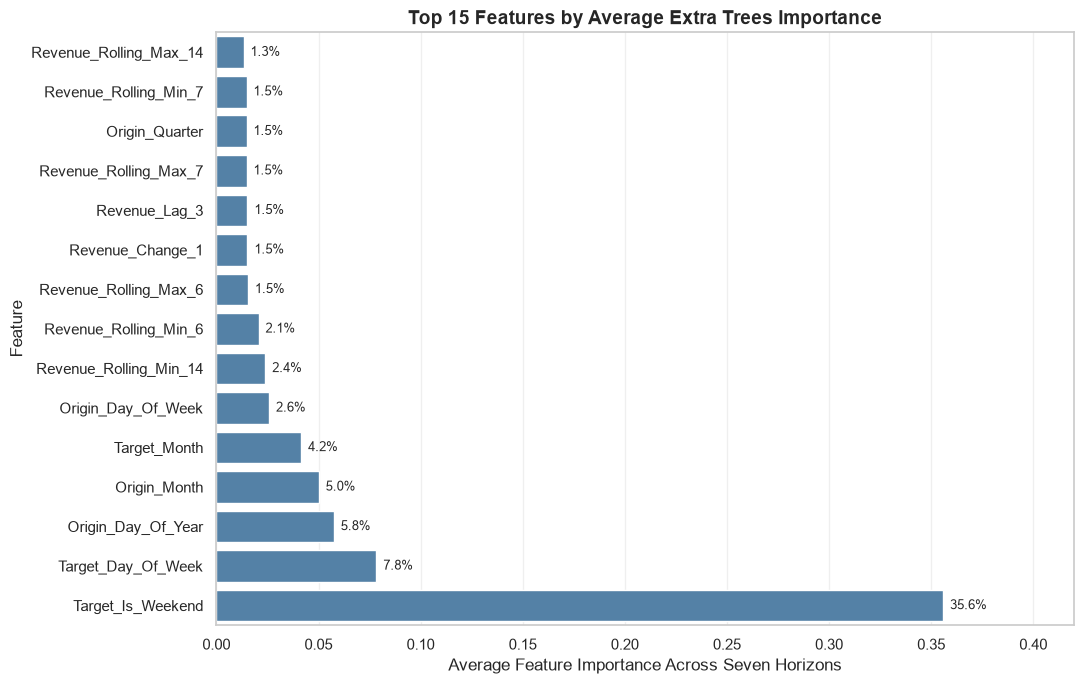

Figure Saved: D:\Projects\ML and Data Science\Retail Sales Dynamics\reports\figures\overall_feature_importance.png
Features Visualized: 15
Forecasting Horizons: 7

Overall Feature Importance Visualization Completed


In [10]:
top_features_df = (
    aggregated_feature_importance_df
    .head(15)
    .sort_values("Mean_Importance", ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=top_features_df,
    x="Mean_Importance",
    y="Feature_Group",
    color="steelblue",
    errorbar=None,
    ax=ax
)

for bar in ax.patches:
    width = bar.get_width()

    ax.annotate(
        f"{width:.1%}",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Top 15 Features by Average Extra Trees Importance",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Average Feature Importance Across Seven Horizons")
ax.set_ylabel("Feature")

ax.set_xlim(
    0,
    top_features_df["Mean_Importance"].max() * 1.18
)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

figure_path = (
    figures_dir / "overall_feature_importance.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure Saved:", figure_path)
print("Features Visualized:", len(top_features_df))
print("Forecasting Horizons:", forecast_horizon)

print("\nOverall Feature Importance Visualization Completed")

**Key Observations**
- **Dominant Calendar Influence:** Target_Is_Weekend leads the feature importance ranking at 35.59%, followed by Target_Day_Of_Week at 7.83%, highlighting the Extra Trees models' reliance on trading-calendar information.
- **Historical Revenue Contributions:** Rolling revenue statistics, lagged revenue, and revenue changes appear among the top 15 features, although their individual importance scores are considerably lower than those of the leading calendar features.

#### Analyzing Feature Importance Across Forecasting Horizons

In [11]:
top_feature_groups = (
    aggregated_feature_importance_df
    .head(10)["Feature_Group"]
    .tolist()
)

horizon_importance_df = (
    normalized_importance_df[
        normalized_importance_df["Feature_Group"].isin(
            top_feature_groups
        )
    ]
    .pivot(
        index="Feature_Group",
        columns="Horizon",
        values="Importance"
    )
    .reindex(top_feature_groups)
)

assert horizon_importance_df.shape == (10, forecast_horizon)
assert not horizon_importance_df.isna().any().any()

print("Top 10 Feature Importance Scores Across Forecasting Horizons:\n")

display(
    horizon_importance_df.style.format("{:.4f}")
)

print("\nMost Important Feature by Horizon:\n")

top_feature_by_horizon_df = (
    normalized_importance_df
    .sort_values(
        ["Horizon", "Importance"],
        ascending=[True, False]
    )
    .groupby("Horizon", as_index=False)
    .first()
    [["Horizon", "Feature_Group", "Importance"]]
)

display(
    top_feature_by_horizon_df.style.format({
        "Importance": "{:.4f}"
    })
)

print("\nHorizon-Wise Feature Importance Analysis Completed")

Top 10 Feature Importance Scores Across Forecasting Horizons:



Horizon,1,2,3,4,5,6,7
Feature_Group,,,,,,,
Target_Is_Weekend,0.3761,0.3773,0.3579,0.3434,0.3504,0.3468,0.3392
Target_Day_Of_Week,0.0916,0.0864,0.0796,0.0697,0.0698,0.0754,0.0758
Origin_Day_Of_Year,0.0546,0.0594,0.0557,0.0542,0.0478,0.0567,0.0743
Origin_Month,0.0423,0.0500,0.0470,0.0302,0.0422,0.0498,0.0895
Target_Month,0.0274,0.0410,0.0308,0.0390,0.0403,0.0579,0.0543
Origin_Day_Of_Week,0.0311,0.0223,0.0396,0.0257,0.0100,0.0095,0.0422
Revenue_Rolling_Min_14,0.0748,0.0234,0.0201,0.0039,0.0316,0.0059,0.0077
Revenue_Rolling_Min_6,0.0063,0.0031,0.0146,0.0189,0.0377,0.0279,0.0359
Revenue_Rolling_Max_6,0.0281,0.0311,0.0264,0.0166,0.0003,0.0016,0.0043



Most Important Feature by Horizon:



,Horizon,Feature_Group,Importance
0,1,Target_Is_Weekend,0.3761
1,2,Target_Is_Weekend,0.3773
2,3,Target_Is_Weekend,0.3579
3,4,Target_Is_Weekend,0.3434
4,5,Target_Is_Weekend,0.3504
5,6,Target_Is_Weekend,0.3468
6,7,Target_Is_Weekend,0.3392



Horizon-Wise Feature Importance Analysis Completed


**Key Observations**
- **Consistent Weekend Influence:** Target_Is_Weekend ranks first across all seven horizons, with importance ranging from 33.92% to 37.73%, demonstrating consistent reliance on the target trading day's weekend indicator.
- **Changing Feature Contributions:** Weekend importance declines from 37.61% at Horizon 1 to 33.92% at Horizon 7, while Origin_Month increases from 4.23% to 8.95%, indicating changes in the models' relative reliance on calendar features across forecasting horizons.

#### Visualizing Horizon-Wise Feature Importance

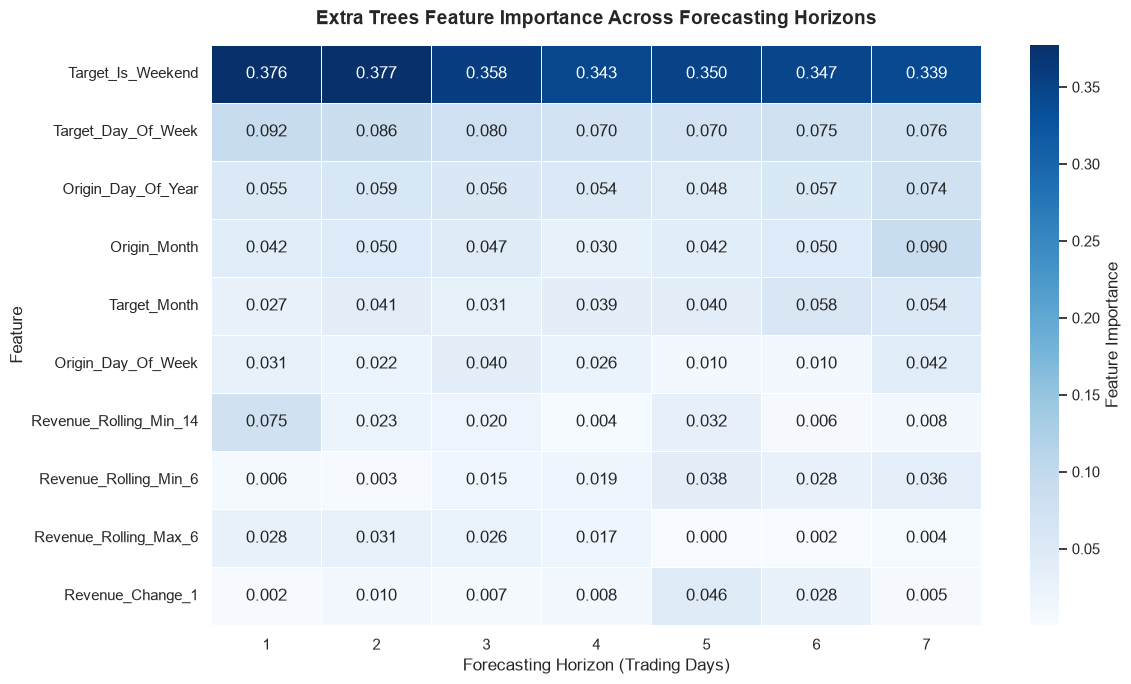

Figure Saved: D:\Projects\ML and Data Science\Retail Sales Dynamics\reports\figures\horizon_wise_feature_importance.png
Features Visualized: 10
Forecasting Horizons: 7

Horizon-Wise Feature Importance Visualization Completed


In [12]:
fig, ax = plt.subplots(figsize=(12, 7))

sns.heatmap(
    horizon_importance_df,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={
        "label": "Feature Importance"
    },
    ax=ax
)

ax.set_title(
    "Extra Trees Feature Importance Across Forecasting Horizons",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Forecasting Horizon (Trading Days)")
ax.set_ylabel("Feature")

plt.tight_layout()

figure_path = (
    figures_dir / "horizon_wise_feature_importance.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure Saved:", figure_path)
print("Features Visualized:", horizon_importance_df.shape[0])
print("Forecasting Horizons:", horizon_importance_df.shape[1])

print("\nHorizon-Wise Feature Importance Visualization Completed")

**Key Observations**
- **Consistent Forecasting Drivers:** Target_Is_Weekend dominates feature importance across all seven horizons, contributing between 33.92% and 37.73% of the total importance in each Extra Trees model.
- **Horizon-Dependent Contributions:** Calendar and historical revenue features exhibit varying importance across horizons, with Origin_Month becoming more prominent at Horizon 7 and Revenue_Rolling_Min_14 contributing most strongly at Horizon 1.

#### Calculating Permutation Feature Importance for Horizon One

In [14]:
horizon = 1

model = extra_trees_models[horizon]

feature_columns = horizon_feature_columns[horizon]
target_column = horizon_target_columns[horizon]

X_test_h1 = test_df[feature_columns].copy()
y_test_h1 = test_df[target_column].copy()

assert len(X_test_h1) == len(y_test_h1)
assert X_test_h1.shape[1] == model.n_features_in_

baseline_predictions = model.predict(X_test_h1)

baseline_mae = mean_absolute_error(
    y_test_h1,
    baseline_predictions
)

permutation_results = permutation_importance(
    estimator=model,
    X=X_test_h1,
    y=y_test_h1,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_importance_h1_df = (
    pd.DataFrame({
        "Feature": feature_columns,
        "Importance_Mean": permutation_results.importances_mean,
        "Importance_Std": permutation_results.importances_std
    })
    .sort_values(
        "Importance_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

print(f"Horizon {horizon} Baseline MAE: {baseline_mae:,.2f}")
print("Features Evaluated:", len(feature_columns))
print("Permutation Repeats:", 5)

print("\nTop 15 Features by Permutation Importance:\n")

display(
    permutation_importance_h1_df.head(15).style.format({
        "Importance_Mean": "{:,.2f}",
        "Importance_Std": "{:,.2f}"
    })
)

print("\nHorizon One Permutation Importance Calculation Completed")

Horizon 1 Baseline MAE: 11,671.25
Features Evaluated: 48
Permutation Repeats: 5

Top 15 Features by Permutation Importance:



,Feature,Importance_Mean,Importance_Std
0,Target_Is_Weekend_H1,"3,440.59",733.45
1,Revenue_Rolling_Min_14,829.55,511.57
2,Target_Day_Of_Week_H1,177.95,127.85
3,Origin_Day_Of_Week,56.88,63.82
4,Revenue_Rolling_Mean_6,42.74,50.04
5,Revenue_Lag_30,41.63,12.49
6,Revenue_Lag_3,37.25,13.20
7,Revenue_Rolling_Min_7,30.47,80.64
8,Revenue_Rolling_Max_6,24.93,172.61
9,Revenue_Lag_12,24.52,9.19



Horizon One Permutation Importance Calculation Completed


**Key Observations**
- **Dominant Permutation Importance:** Shuffling Target_Is_Weekend_H1 increased Horizon 1 MAE by an average of 3,440.59, making it the most influential feature under the permutation test.
- **Historical Revenue Contribution:** Revenue_Rolling_Min_14 ranked second with an average MAE increase of 829.55, while the remaining features showed considerably smaller individual effects, indicating that the model relies most heavily on weekend information and selected historical revenue patterns.

#### Visualizing Horizon One Permutation Feature Importance

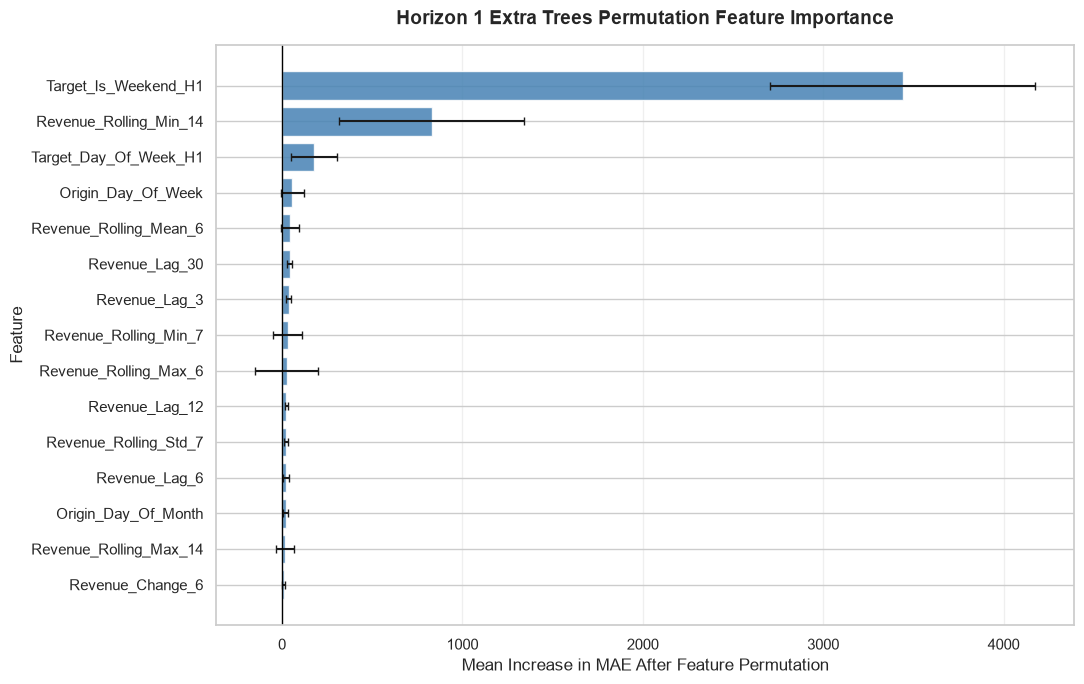

Figure Saved: D:\Projects\ML and Data Science\Retail Sales Dynamics\reports\figures\horizon_1_permutation_importance.png
Features Visualized: 15
Permutation Repeats: 5
Original Horizon 1 MAE: 11,671.25

Permutation Feature Importance Visualization Completed


In [15]:
top_permutation_features_df = (
    permutation_importance_h1_df
    .head(15)
    .sort_values(
        "Importance_Mean",
        ascending=True
    )
)

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    top_permutation_features_df["Feature"],
    top_permutation_features_df["Importance_Mean"],
    xerr=top_permutation_features_df["Importance_Std"],
    color="steelblue",
    alpha=0.85,
    capsize=3
)

ax.axvline(
    x=0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Horizon 1 Extra Trees Permutation Feature Importance",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Mean Increase in MAE After Feature Permutation")
ax.set_ylabel("Feature")

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

figure_path = (
    figures_dir / "horizon_1_permutation_importance.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure Saved:", figure_path)
print("Features Visualized:", len(top_permutation_features_df))
print("Permutation Repeats:", 5)
print(f"Original Horizon 1 MAE: {baseline_mae:,.2f}")

print("\nPermutation Feature Importance Visualization Completed")

**Key Observations**
- **Weekend Feature Dominance:** Permuting Target_Is_Weekend_H1 increased forecasting MAE by an average of 3,440.59, substantially exceeding the impact of other features.
- **Secondary Revenue Influence:** Revenue_Rolling_Min_14 produced the second-largest average MAE increase of 829.55, while the remaining features exhibited smaller effects, with several estimates showing considerable variability across permutation repeats.

#### Comparing Impurity-Based and Permutation Feature Importance

In [16]:
impurity_importance_h1_df = (
    feature_importance_df[
        feature_importance_df["Horizon"] == 1
    ]
    [["Feature", "Importance"]]
    .rename(
        columns={
            "Importance": "Impurity_Importance"
        }
    )
)

importance_comparison_df = (
    impurity_importance_h1_df
    .merge(
        permutation_importance_h1_df[
            ["Feature", "Importance_Mean"]
        ],
        on="Feature",
        how="inner"
    )
    .rename(
        columns={
            "Importance_Mean": "Permutation_Importance"
        }
    )
)

assert len(importance_comparison_df) == 48

importance_comparison_df["Impurity_Rank"] = (
    importance_comparison_df["Impurity_Importance"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

importance_comparison_df["Permutation_Rank"] = (
    importance_comparison_df["Permutation_Importance"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

importance_comparison_df["Rank_Difference"] = (
    importance_comparison_df["Impurity_Rank"]
    - importance_comparison_df["Permutation_Rank"]
)

importance_comparison_df = (
    importance_comparison_df
    .sort_values(
        "Impurity_Rank"
    )
    .reset_index(drop=True)
)

rank_correlation = (
    importance_comparison_df["Impurity_Rank"]
    .corr(
        importance_comparison_df["Permutation_Rank"],
        method="spearman"
    )
)

print("Horizon 1 Feature Importance Method Comparison:\n")

display(
    importance_comparison_df.head(15).style.format({
        "Impurity_Importance": "{:.4f}",
        "Permutation_Importance": "{:,.2f}"
    })
)

print(f"\nSpearman Rank Correlation: {rank_correlation:.4f}")
print("Features Compared:", len(importance_comparison_df))

print("\nFeature Importance Method Comparison Completed")

Horizon 1 Feature Importance Method Comparison:



,Feature,Impurity_Importance,Permutation_Importance,Impurity_Rank,Permutation_Rank,Rank_Difference
0,Target_Is_Weekend_H1,0.3761,"3,440.59",1,1,0
1,Target_Day_Of_Week_H1,0.0916,177.95,2,3,-1
2,Revenue_Rolling_Min_14,0.0748,829.55,3,2,1
3,Origin_Day_Of_Year,0.0546,0.00,4,21,-17
4,Origin_Month,0.0423,0.00,5,21,-16
5,Origin_Day_Of_Week,0.0311,56.88,6,4,2
6,Revenue_Rolling_Max_6,0.0281,24.93,7,9,-2
7,Target_Month_H1,0.0274,-0.00,8,31,-23
8,Revenue_Rolling_Max_7,0.0231,8.70,9,16,-7
9,Revenue_Rolling_Mean_6,0.0230,42.74,10,5,5



Spearman Rank Correlation: 0.4416
Features Compared: 48

Feature Importance Method Comparison Completed


**Key Observations**
- **Agreement on Leading Features:** Both methods rank Target_Is_Weekend_H1 first, while Target_Day_Of_Week_H1 and Revenue_Rolling_Min_14 occupy the next two positions, confirming their prominence in Horizon 1 predictions.
- **Moderate Ranking Agreement:** The Spearman correlation of 0.4416 indicates moderate agreement between importance methods, with features such as Origin_Day_Of_Year and Origin_Month receiving relatively high impurity importance but negligible permutation importance.

#### Visualizing Feature Importance Ranking Differences

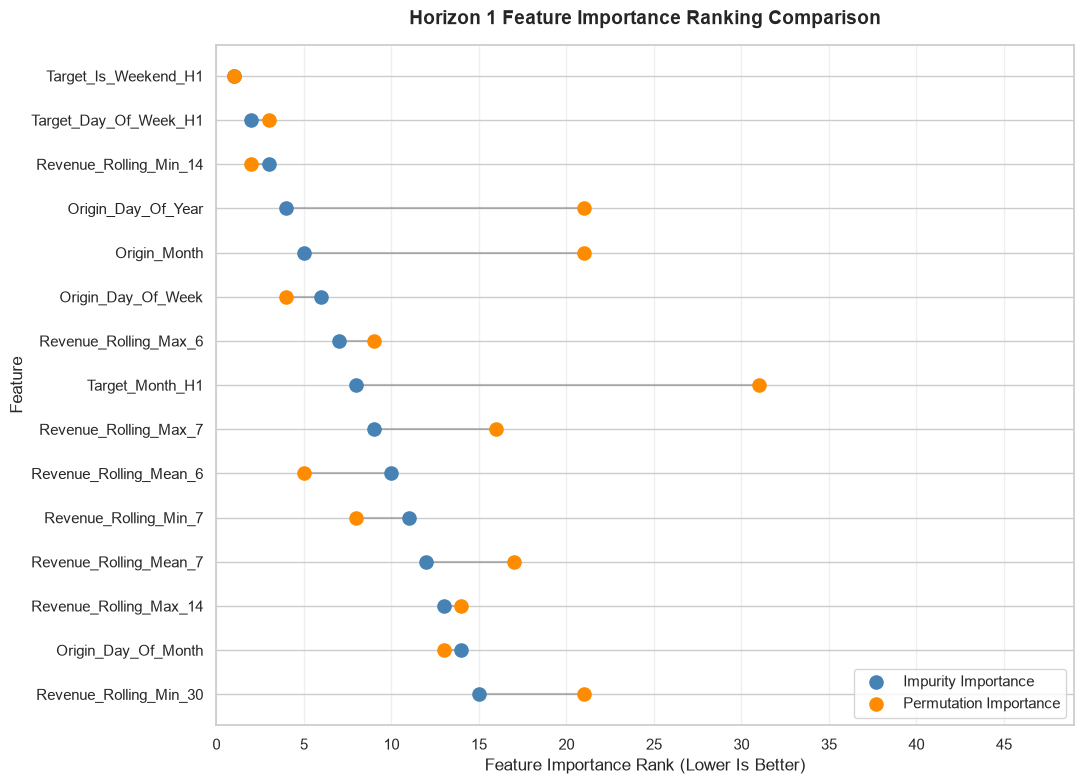

Figure Saved: D:\Projects\ML and Data Science\Retail Sales Dynamics\reports\figures\feature_importance_ranking_comparison.png
Features Compared: 15
Spearman Rank Correlation: 0.4416

Feature Importance Ranking Visualization Completed


In [17]:
top_comparison_df = (
    importance_comparison_df
    .head(15)
    .sort_values(
        "Impurity_Rank",
        ascending=False
    )
)

fig, ax = plt.subplots(figsize=(11, 8))

y_positions = np.arange(len(top_comparison_df))

ax.scatter(
    top_comparison_df["Impurity_Rank"],
    y_positions,
    s=90,
    label="Impurity Importance",
    color="steelblue",
    zorder=3
)

ax.scatter(
    top_comparison_df["Permutation_Rank"],
    y_positions,
    s=90,
    label="Permutation Importance",
    color="darkorange",
    zorder=3
)

for index, row in enumerate(top_comparison_df.itertuples()):
    ax.plot(
        [row.Impurity_Rank, row.Permutation_Rank],
        [index, index],
        color="gray",
        alpha=0.5,
        linewidth=1.5
    )

ax.set_yticks(y_positions)
ax.set_yticklabels(top_comparison_df["Feature"])

ax.set_xlabel("Feature Importance Rank (Lower Is Better)")
ax.set_ylabel("Feature")

ax.set_title(
    "Horizon 1 Feature Importance Ranking Comparison",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlim(0, 49)
ax.set_xticks(np.arange(0, 49, 5))

ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right")

plt.tight_layout()

figure_path = (
    figures_dir / "feature_importance_ranking_comparison.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure Saved:", figure_path)
print("Features Compared:", len(top_comparison_df))
print(f"Spearman Rank Correlation: {rank_correlation:.4f}")

print("\nFeature Importance Ranking Visualization Completed")

**Key Observations**
- **Consistent Leading Features:** Target_Is_Weekend_H1 ranks first under both importance methods, while Revenue_Rolling_Min_14 and Target_Day_Of_Week_H1 remain among the three highest-ranked features.
- **Differences in Feature Rankings:** The moderate Spearman correlation of 0.4416 highlights differences between the methods, particularly for calendar variables that receive high impurity importance but negligible permutation importance.

#### Analyzing AutoReg Model Coefficients

In [18]:
autoreg_parameters = pd.Series(
    autoreg_model.params
)

autoreg_pvalues = pd.Series(
    autoreg_model.pvalues,
    index=autoreg_parameters.index
)

autoreg_coefficient_df = pd.DataFrame({
    "Parameter": autoreg_parameters.index,
    "Coefficient": autoreg_parameters.values,
    "P_Value": autoreg_pvalues.values
})

autoreg_coefficient_df["Absolute_Coefficient"] = (
    autoreg_coefficient_df["Coefficient"].abs()
)

autoreg_coefficient_df["Significant_5pct"] = (
    autoreg_coefficient_df["P_Value"] < 0.05
)

autoreg_coefficient_df = (
    autoreg_coefficient_df
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

print("AutoReg Model Coefficient Analysis:\n")

display(
    autoreg_coefficient_df.style.format({
        "Coefficient": "{:,.4f}",
        "P_Value": "{:.4f}",
        "Absolute_Coefficient": "{:,.4f}"
    })
)

print("\nAutoReg Model Information:")
print("Model Type:", type(autoreg_model.model).__name__)
print("Observations:", autoreg_model.nobs)
print("AIC:", round(autoreg_model.aic, 2))
print("BIC:", round(autoreg_model.bic, 2))

print("\nAutoReg Coefficient Analysis Completed")

AutoReg Model Coefficient Analysis:



,Parameter,Coefficient,P_Value,Absolute_Coefficient,Significant_5pct
0,const,"11,211.5672",0.0004,"11,211.5672",True
1,Daily_Revenue.L6,0.2951,0.0000,0.2951,True
2,Daily_Revenue.L12,0.1797,0.0077,0.1797,True
3,Daily_Revenue.L1,0.1004,0.0967,0.1004,False
4,Daily_Revenue.L3,0.0486,0.4188,0.0486,False
5,Daily_Revenue.L2,-0.0415,0.4980,0.0415,False



AutoReg Model Information:
Model Type: AutoReg
Observations: 232
AIC: 5040.68
BIC: 5064.81

AutoReg Coefficient Analysis Completed


**Key Observations**
- **Significant Seasonal Lags:** Revenue_Lag_6 (0.2951, p < 0.001) and Revenue_Lag_12 (0.1797, p = 0.0077) exhibit statistically significant positive coefficients, highlighting recurring revenue patterns across six- and twelve-trading-day intervals.
- **Limited Short-Term Lag Significance:** Revenue_Lag_1, Revenue_Lag_2, and Revenue_Lag_3 are not statistically significant at the 5% level, suggesting weaker individual evidence for their contributions after accounting for the other included lags.

#### Analyzing SARIMA Model Parameters

In [20]:
sarima_parameters = pd.Series(
    sarima_model.params
)

sarima_pvalues = pd.Series(
    sarima_model.pvalues,
    index=sarima_parameters.index
)

sarima_parameter_df = pd.DataFrame({
    "Parameter": sarima_parameters.index,
    "Coefficient": sarima_parameters.values,
    "P_Value": sarima_pvalues.values
})

sarima_parameter_df["Significant_5pct"] = (
    sarima_parameter_df["P_Value"] < 0.05
)

print("SARIMA Model Parameter Analysis:\n")

display(
    sarima_parameter_df.style.format({
        "Coefficient": "{:,.4f}",
        "P_Value": "{:.4f}"
    })
)

print("\nSARIMA Model Information:")
print("Non-Seasonal Order:", sarima_model.model.order)
print("Seasonal Order:", sarima_model.model.seasonal_order)
print("Observations:", sarima_model.nobs)
print("AIC:", round(sarima_model.aic, 2))
print("BIC:", round(sarima_model.bic, 2))

print("\nSARIMA Parameter Analysis Completed")

SARIMA Model Parameter Analysis:



,Parameter,Coefficient,P_Value,Significant_5pct
0,intercept,"20,170.7658",0.0398,True
1,ar.L1,-0.6656,0.0039,True
2,ma.L1,0.7560,0.0001,True
3,ar.S.L6,0.5571,0.0010,True
4,ma.S.L6,-0.2075,0.2906,False
5,sigma2,"193,701,961.6569",0.0000,True



SARIMA Model Information:
Non-Seasonal Order: (1, 0, 1)
Seasonal Order: (1, 0, 1, 6)
Observations: 244
AIC: 5132.76
BIC: 5153.54

SARIMA Parameter Analysis Completed


**Key Observations**
- **Significant Seasonal Dependence:** The seasonal autoregressive coefficient at Lag 6 (0.5571, p = 0.0010) is statistically significant, supporting the presence of recurring six-trading-day revenue patterns.
- **Non-Seasonal Dynamics:** The AR(1) coefficient (-0.6656) and MA(1) coefficient (0.7560) are statistically significant, while the seasonal MA(6) coefficient (-0.2075, p = 0.2906) is not significant at the 5% level.

#### Comparing Temporal Patterns Across Statistical Models

In [21]:
autoreg_lag_df = autoreg_coefficient_df[
    autoreg_coefficient_df["Parameter"].str.contains(
        r"\.L\d+$",
        regex=True
    )
].copy()

sarima_dynamic_df = sarima_parameter_df[
    sarima_parameter_df["Parameter"].str.match(
        r"^(ar|ma)\.",
        na=False
    )
].copy()

temporal_model_summary_df = pd.DataFrame([
    {
        "Model": "AutoReg",
        "Temporal_Structure": "Lags 1, 2, 3, 6, 12",
        "Significant_Parameters": ", ".join(
            autoreg_lag_df.loc[
                autoreg_lag_df["Significant_5pct"],
                "Parameter"
            ]
        ),
        "Significant_Count": int(
            autoreg_lag_df["Significant_5pct"].sum()
        ),
        "Total_Dynamic_Parameters": len(autoreg_lag_df)
    },
    {
        "Model": "SARIMA",
        "Temporal_Structure": "ARIMA(1,0,1) × (1,0,1,6)",
        "Significant_Parameters": ", ".join(
            sarima_dynamic_df.loc[
                sarima_dynamic_df["Significant_5pct"],
                "Parameter"
            ]
        ),
        "Significant_Count": int(
            sarima_dynamic_df["Significant_5pct"].sum()
        ),
        "Total_Dynamic_Parameters": len(sarima_dynamic_df)
    }
])

print("Statistical Model Temporal Structure Comparison:\n")

display(temporal_model_summary_df)

print("\nShared Temporal Finding:")

autoreg_seasonal_significant = (
    autoreg_lag_df.loc[
        autoreg_lag_df["Parameter"] == "Daily_Revenue.L6",
        "Significant_5pct"
    ].any()
)

sarima_seasonal_significant = (
    sarima_dynamic_df.loc[
        sarima_dynamic_df["Parameter"] == "ar.S.L6",
        "Significant_5pct"
    ].any()
)

print(
    "Significant Six-Trading-Day Dependence in Both Models:",
    bool(
        autoreg_seasonal_significant
        and sarima_seasonal_significant
    )
)

print("\nStatistical Model Temporal Comparison Completed")

Statistical Model Temporal Structure Comparison:



,Model,Temporal_Structure,Significant_Parameters,Significant_Count,Total_Dynamic_Parameters
0,AutoReg,"Lags 1, 2, 3, 6, 12","Daily_Revenue.L6, Daily_Revenue.L12",2,5
1,SARIMA,"ARIMA(1,0,1) × (1,0,1,6)","ar.L1, ma.L1, ar.S.L6",3,4



Shared Temporal Finding:
Significant Six-Trading-Day Dependence in Both Models: True

Statistical Model Temporal Comparison Completed


#### Analyzing Forecast Contributions Within Voting Hybrid

In [22]:
ensemble_components = [
    "Extra_Trees",
    "AutoReg",
    "SARIMA"
]

ensemble_analysis_df = rolling_predictions_df.copy()

ensemble_analysis_df["Reconstructed_Voting_Hybrid"] = (
    ensemble_analysis_df[ensemble_components].mean(axis=1)
)

assert np.allclose(
    ensemble_analysis_df["Reconstructed_Voting_Hybrid"],
    ensemble_analysis_df["Voting_Hybrid"],
    rtol=1e-6,
    atol=1e-4
), "Ensemble reconstruction mismatch"

ensemble_analysis_df["Component_Disagreement"] = (
    ensemble_analysis_df[ensemble_components].std(
        axis=1,
        ddof=0
    )
)

ensemble_analysis_df["Ensemble_Absolute_Error"] = (
    ensemble_analysis_df["Actual"]
    - ensemble_analysis_df["Voting_Hybrid"]
).abs()

ensemble_component_summary_df = pd.DataFrame({
    "Model": ensemble_components,
    "Weight": [1 / 3] * 3,
    "Mean_Prediction": [
        ensemble_analysis_df[model].mean()
        for model in ensemble_components
    ],
    "MAE": [
        mean_absolute_error(
            ensemble_analysis_df["Actual"],
            ensemble_analysis_df[model]
        )
        for model in ensemble_components
    ]
})

print("Voting Hybrid Component Summary:\n")

display(
    ensemble_component_summary_df.style.format({
        "Weight": "{:.2%}",
        "Mean_Prediction": "{:,.2f}",
        "MAE": "{:,.2f}"
    })
)

print("\nEnsemble Forecast Diagnostics:")
print(
    "Mean Voting Hybrid Prediction:",
    f"{ensemble_analysis_df['Voting_Hybrid'].mean():,.2f}"
)
print(
    "Mean Actual Revenue:",
    f"{ensemble_analysis_df['Actual'].mean():,.2f}"
)
print(
    "Mean Component Disagreement:",
    f"{ensemble_analysis_df['Component_Disagreement'].mean():,.2f}"
)
print(
    "Median Component Disagreement:",
    f"{ensemble_analysis_df['Component_Disagreement'].median():,.2f}"
)
print(
    "Voting Hybrid MAE:",
    f"{ensemble_analysis_df['Ensemble_Absolute_Error'].mean():,.2f}"
)

print("\nVoting Hybrid Component Analysis Completed")

Voting Hybrid Component Summary:



,Model,Weight,Mean_Prediction,MAE
0,Extra_Trees,33.33%,"39,520.24","12,374.70"
1,AutoReg,33.33%,"42,138.31","13,303.88"
2,SARIMA,33.33%,"38,563.27","14,131.27"



Ensemble Forecast Diagnostics:
Mean Voting Hybrid Prediction: 40,073.94
Mean Actual Revenue: 48,732.53
Mean Component Disagreement: 3,645.69
Median Component Disagreement: 3,093.39
Voting Hybrid MAE: 12,465.39

Voting Hybrid Component Analysis Completed


**Key Observations**
- **Component Forecasting Performance:** Extra Trees achieved the lowest test MAE of 12,374.70, followed by AutoReg (13,303.88) and SARIMA (14,131.27), despite all three receiving equal weights in Voting Hybrid.
- **Ensemble Underprediction:** Voting Hybrid predicted an average revenue of 40,073.94 against actual average revenue of 48,732.53, indicating systematic underprediction, while component forecasts differed by an average standard deviation of 3,645.69.

#### Analyzing Ensemble Disagreement Across Forecasting Horizons

In [23]:
horizon_disagreement_df = (
    ensemble_analysis_df
    .groupby("Horizon", as_index=False)
    .agg(
        Forecasts=("Actual", "size"),
        Mean_Component_Disagreement=(
            "Component_Disagreement",
            "mean"
        ),
        Median_Component_Disagreement=(
            "Component_Disagreement",
            "median"
        ),
        Mean_Actual_Revenue=("Actual", "mean"),
        Mean_Ensemble_Prediction=("Voting_Hybrid", "mean"),
        Ensemble_MAE=("Ensemble_Absolute_Error", "mean")
    )
)

horizon_disagreement_df["Mean_Forecast_Bias"] = (
    horizon_disagreement_df["Mean_Actual_Revenue"]
    - horizon_disagreement_df["Mean_Ensemble_Prediction"]
)

assert len(horizon_disagreement_df) == forecast_horizon
assert (horizon_disagreement_df["Forecasts"] == len(test_df)).all()

print("Ensemble Disagreement Across Forecasting Horizons:\n")

display(
    horizon_disagreement_df.style.format({
        "Mean_Component_Disagreement": "{:,.2f}",
        "Median_Component_Disagreement": "{:,.2f}",
        "Mean_Actual_Revenue": "{:,.2f}",
        "Mean_Ensemble_Prediction": "{:,.2f}",
        "Ensemble_MAE": "{:,.2f}",
        "Mean_Forecast_Bias": "{:+,.2f}"
    })
)

disagreement_error_correlation = (
    ensemble_analysis_df["Component_Disagreement"]
    .corr(
        ensemble_analysis_df["Ensemble_Absolute_Error"]
    )
)

print(
    "\nCorrelation Between Component Disagreement and Absolute Error:",
    f"{disagreement_error_correlation:.4f}"
)

print("\nHorizon-Wise Ensemble Disagreement Analysis Completed")

Ensemble Disagreement Across Forecasting Horizons:



,Horizon,Forecasts,Mean_Component_Disagreement,Median_Component_Disagreement,Mean_Actual_Revenue,Mean_Ensemble_Prediction,Ensemble_MAE,Mean_Forecast_Bias
0,1,55,"3,669.34","2,905.14","48,069.16","40,302.84","11,850.90","+7,766.32"
1,2,55,"4,264.25","3,750.96","47,733.56","40,467.24","11,653.01","+7,266.32"
2,3,55,"3,151.22","2,482.81","48,970.68","40,414.96","12,619.77","+8,555.72"
3,4,55,"3,291.69","2,824.58","48,834.45","40,136.98","12,422.31","+8,697.47"
4,5,55,"3,167.86","2,591.42","49,299.16","40,063.75","12,665.20","+9,235.41"
5,6,55,"3,449.62","3,101.59","49,338.20","40,932.11","12,216.19","+8,406.09"
6,7,55,"4,525.87","3,945.97","48,882.50","38,199.70","13,830.32","+10,682.80"



Correlation Between Component Disagreement and Absolute Error: -0.1396

Horizon-Wise Ensemble Disagreement Analysis Completed


**Key Observations**
- **Horizon-Wise Forecasting Differences:** Component disagreement varies across forecasting horizons, reaching its highest average of 4,525.87 at Horizon 7, which also records the highest ensemble MAE of 13,830.32.
- **Persistent Forecast Underprediction:** Voting Hybrid underpredicts average revenue across all seven horizons, with the largest mean bias of 10,682.80 at Horizon 7. The weak negative correlation (-0.1396) indicates that component disagreement is not a reliable standalone indicator of forecasting error.

#### Visualizing Ensemble Disagreement Across Forecasting Horizons

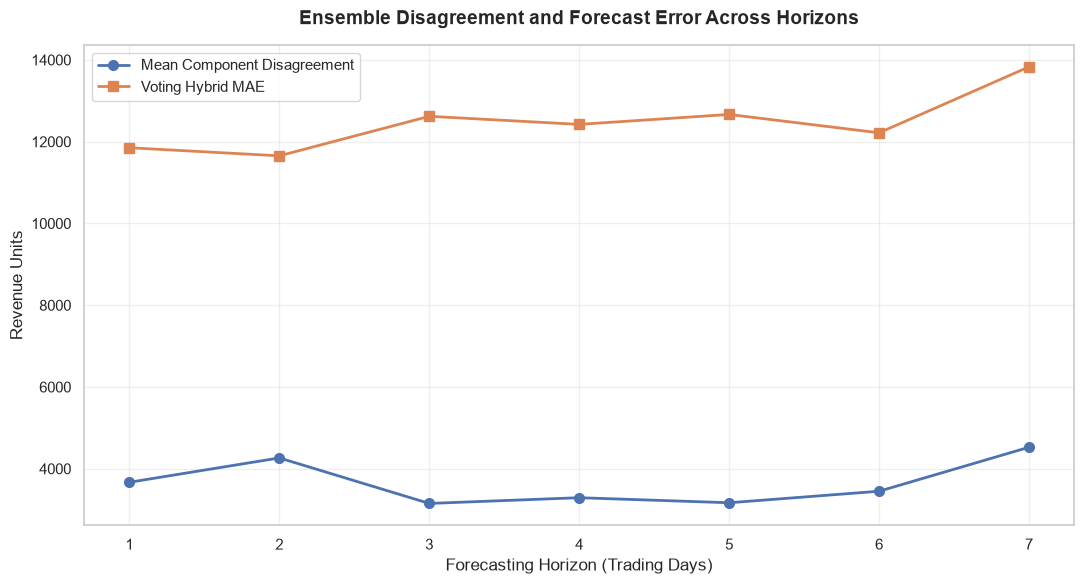

Figure Saved: D:\Projects\ML and Data Science\Retail Sales Dynamics\reports\figures\ensemble_disagreement_by_horizon.png
Forecasting Horizons: 7
Overall Disagreement-Error Correlation: -0.1396

Ensemble Disagreement Visualization Completed


In [24]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    horizon_disagreement_df["Horizon"],
    horizon_disagreement_df["Mean_Component_Disagreement"],
    marker="o",
    linewidth=2,
    markersize=7,
    label="Mean Component Disagreement"
)

ax.plot(
    horizon_disagreement_df["Horizon"],
    horizon_disagreement_df["Ensemble_MAE"],
    marker="s",
    linewidth=2,
    markersize=7,
    label="Voting Hybrid MAE"
)

ax.set_title(
    "Ensemble Disagreement and Forecast Error Across Horizons",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Forecasting Horizon (Trading Days)")
ax.set_ylabel("Revenue Units")

ax.set_xticks(range(1, forecast_horizon + 1))

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

figure_path = (
    figures_dir / "ensemble_disagreement_by_horizon.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure Saved:", figure_path)
print("Forecasting Horizons:", len(horizon_disagreement_df))
print(
    "Overall Disagreement-Error Correlation:",
    f"{disagreement_error_correlation:.4f}"
)

print("\nEnsemble Disagreement Visualization Completed")

**Key Observations**
- **Highest Disagreement at Horizon Seven:** Mean component disagreement reaches 4,525.87 at Horizon 7, alongside the highest Voting Hybrid MAE of 13,830.32.
- **Weak Disagreement–Error Relationship:** Component disagreement fluctuates across forecasting horizons, while its overall correlation with absolute forecasting error is only -0.1396, indicating limited usefulness as a standalone error indicator.

#### Saving Model Explainability Artifacts

In [25]:
explainability_artifacts = {
    "extra_trees_feature_importance.csv": feature_importance_df,
    "aggregated_feature_importance.csv": aggregated_feature_importance_df,
    "horizon_feature_importance.csv": normalized_importance_df,
    "horizon_1_permutation_importance.csv": permutation_importance_h1_df,
    "feature_importance_method_comparison.csv": importance_comparison_df,
    "autoreg_coefficients.csv": autoreg_coefficient_df,
    "sarima_parameters.csv": sarima_parameter_df,
    "statistical_model_comparison.csv": temporal_model_summary_df,
    "ensemble_component_summary.csv": ensemble_component_summary_df,
    "ensemble_horizon_disagreement.csv": horizon_disagreement_df
}

saved_explainability_paths = {}

for filename, dataframe in explainability_artifacts.items():
    output_path = artifacts_dir / filename

    dataframe.to_csv(
        output_path,
        index=False
    )

    assert output_path.exists()

    saved_explainability_paths[filename] = output_path

explainability_summary = {
    "final_model": final_model_config["model_name"],
    "forecast_horizon": forecast_horizon,
    "extra_trees_models": len(extra_trees_models),
    "features_per_horizon": len(horizon_feature_columns[1]),
    "consolidated_feature_groups": len(aggregated_feature_importance_df),
    "top_feature": str(
        aggregated_feature_importance_df.iloc[0]["Feature_Group"]
    ),
    "top_feature_mean_importance": float(
        aggregated_feature_importance_df.iloc[0]["Mean_Importance"]
    ),
    "horizon_1_permutation_baseline_mae": float(baseline_mae),
    "feature_importance_rank_correlation": float(rank_correlation),
    "ensemble_disagreement_error_correlation": float(
        disagreement_error_correlation
    ),
    "ensemble_mean_component_disagreement": float(
        ensemble_analysis_df["Component_Disagreement"].mean()
    ),
    "ensemble_test_mae": float(
        ensemble_analysis_df["Ensemble_Absolute_Error"].mean()
    )
}

summary_path = (
    artifacts_dir / "model_explainability_summary.json"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        explainability_summary,
        file,
        indent=4
    )

assert summary_path.exists()

print("Saved Model Explainability Artifacts:\n")

for filename, path in saved_explainability_paths.items():
    print(f"{filename}: {path}")

print(f"model_explainability_summary.json: {summary_path}")

print(
    "\nTotal Explainability Artifacts Saved:",
    len(saved_explainability_paths) + 1
)

print("\nModel Explainability Results Saved Successfully")

Saved Model Explainability Artifacts:

extra_trees_feature_importance.csv: D:\Projects\ML and Data Science\Retail Sales Dynamics\artifacts\extra_trees_feature_importance.csv
aggregated_feature_importance.csv: D:\Projects\ML and Data Science\Retail Sales Dynamics\artifacts\aggregated_feature_importance.csv
horizon_feature_importance.csv: D:\Projects\ML and Data Science\Retail Sales Dynamics\artifacts\horizon_feature_importance.csv
horizon_1_permutation_importance.csv: D:\Projects\ML and Data Science\Retail Sales Dynamics\artifacts\horizon_1_permutation_importance.csv
feature_importance_method_comparison.csv: D:\Projects\ML and Data Science\Retail Sales Dynamics\artifacts\feature_importance_method_comparison.csv
autoreg_coefficients.csv: D:\Projects\ML and Data Science\Retail Sales Dynamics\artifacts\autoreg_coefficients.csv
sarima_parameters.csv: D:\Projects\ML and Data Science\Retail Sales Dynamics\artifacts\sarima_parameters.csv
statistical_model_comparison.csv: D:\Projects\ML and Dat

**Key Observations**
- **Explainability Artifacts Preserved:** Ten CSV files and one JSON summary have been saved successfully, covering feature importance, statistical model parameters, and ensemble forecasting diagnostics.
- **Reproducible Model Interpretation:** The saved artifacts support consistent interpretation of forecasting behavior across all seven horizons without requiring repeated model fitting or explainability calculations.

#### Summarizing Model Explainability Findings

**Key Findings**

- **Calendar-Driven Forecasting:** Target_Is_Weekend is the most influential Extra Trees feature across all seven forecasting horizons, with a mean feature importance of approximately 35.59%.
- **Seasonal Revenue Patterns:** AutoReg and SARIMA both identify statistically significant six-trading-day autoregressive relationships, supporting the importance of recurring trading-cycle patterns.
- **Feature Importance Validation:** Permutation importance confirms the importance of Target_Is_Weekend for Horizon 1, although the moderate ranking correlation (0.4416) indicates differences between impurity-based and permutation-based explanations.
- **Ensemble Forecasting Behavior:** Voting Hybrid combines Extra Trees, AutoReg, and SARIMA with equal weights. Extra Trees achieves the lowest individual test MAE of 12,374.70, compared with the ensemble's MAE of 12,465.39.
- **Forecasting Limitations:** Voting Hybrid systematically underpredicts revenue across all seven horizons, with the largest mean forecast bias occurring at Horizon 7.

**Conclusion**

The explainability analysis demonstrates that calendar characteristics, recurring trading-cycle patterns, and historical revenue behavior contribute to daily revenue forecasting. While the validation-selected Voting Hybrid model improves upon the seasonal naive baseline on the test set, persistent underprediction and weaker performance at longer horizons highlight opportunities for future improvement.

Feature importance and statistical model coefficients describe predictive relationships rather than causal effects. The analysis also assumes that future trading dates are known when generating forecasts.